In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\Ayush Kumar
[nltk_data]     Jha\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [8]:
messages = pd.read_csv(
    "indian_civic_language_moderation_hindi_english.csv"
)

messages.head(5)

,message_id,message,label,language,abuse_type,split
0,NAGRIC-01948,I request the concerned department to address ...,good,English,none,train
1,NAGRIC-01310,जन सुरक्षा के लिए Sector 14 पर damaged school ...,good,Hindi,none,train
2,NAGRIC-01607,Please repair the streetlight outage near बस स...,good,English,none,train
3,NAGRIC-02628,तुम लोगों को कुछ आता भी है? main market की dam...,bad,Hindi,profanity_or_personal_abuse,validation
4,NAGRIC-02442,जन सुरक्षा के लिए community centre पर damaged ...,good,Hindi,none,train


In [9]:
messages.drop(columns=["message_id","language","abuse_type","split"],inplace=True)

In [10]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download("stopwords")

ps = PorterStemmer()

# English stopwords
english_stopwords = set(stopwords.words("english"))

# Basic Hindi stopwords
hindi_stopwords = {
    "और", "का", "की", "के", "है", "हैं", "था", "थी",
    "थे", "को", "से", "में", "पर", "यह", "वह", "एक",
     "कर", "रहा", "रही", "रहे", "लिए", "तो",
    "भी", "तक", "अपने", "अपनी", "बहुत", "अगर", "लेकिन"
}

corpus = []

for i in range(len(messages)):

    # Read the message as text
    review = str(messages["message"].iloc[i])

    # Keep English letters, Hindi Devanagari, and spaces
    review = re.sub(r"[^a-zA-Z\u0900-\u097F\s]", " ", review)

    # Convert English text to lowercase
    review = review.lower()

    # Tokenize
    words = review.split()

    processed_words = []

    for word in words:

        # Remove stopwords and stem English words
        if word in english_stopwords or word in hindi_stopwords:
            continue

        # Apply Porter stemming only to English words
        if re.fullmatch(r"[a-z]+", word):
            word = ps.stem(word)

        processed_words.append(word)

    review = " ".join(processed_words)

    corpus.append(review)

print(corpus[:5])

[nltk_data] Downloading package stopwords to C:\Users\Ayush Kumar
[nltk_data]     Jha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['request concern depart address pothol metro station', 'जन सुरक्षा sector damag school toilet जल्द ठीक करना आवश्यक है।', 'pleas repair streetlight outag near बस स्टैंड पास affect resid', 'तुम लोगों कुछ आता main market damag footpath ठीक करो बेवकूफ कहीं के।', 'जन सुरक्षा commun centr damag school toilet जल्द ठीक करना आवश्यक है।']


In [11]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = cv.fit_transform(corpus).toarray()

print("Shape:", X.shape)

Shape: (3098, 2123)


In [12]:
y = messages["label"].map({"good":0 , "bad":1})

In [13]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "SVC": SVC()
}

In [14]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


def evaluate_models(X, y, models):
    """
    Takes X, y, and a dictionary of models.
    Splits the data into training and testing sets.
    Trains and evaluates each model.
    Returns a DataFrame containing model names and accuracy scores.
    """

    # Separate dataset into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    models_list = []
    scores = []

    for model_name, model in models.items():

        # Train the model
        model.fit(X_train, y_train)

        # Make predictions
        y_pred = model.predict(X_test)

        # Calculate accuracy
        score = accuracy_score(y_test, y_pred)

        print(f"---- Score for {model_name} ----")
        print(f"Accuracy: {score:.4f}")
        print()

        models_list.append(model_name)
        scores.append(score)

    # Create evaluation report
    report = pd.DataFrame({
        "Model_name": models_list,
        "Accuracy": scores
    })

    return report

In [15]:
report = evaluate_models(X, y, models)

report

---- Score for Multinomial Naive Bayes ----
Accuracy: 1.0000

---- Score for SVC ----
Accuracy: 1.0000



,Model_name,Accuracy
0,Multinomial Naive Bayes,1.0
1,SVC,1.0


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

params = {
    "C": [0.01, 0.1, 1, 10]
}

svc_cv = GridSearchCV(
    estimator=LinearSVC(random_state=42, max_iter=5000),
    param_grid=params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Train and tune the model
svc_cv.fit(X_train, y_train)

print("Best Parameters:", svc_cv.best_params_)
print("Best Cross-Validation Accuracy:", svc_cv.best_score_)

Best Parameters: {'C': 0.01}
Best Cross-Validation Accuracy: 1.0


In [18]:
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

spam_detect_model = LinearSVC(**svc_cv.best_params_)

spam_detect_model.fit(X_train, y_train)

y_pred = spam_detect_model.predict(X_test)

confusion_m = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy of the model is {accuracy:.4f}")
print(f"\nConfusion Matrix:\n{confusion_m}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy of the model is 1.0000

Confusion Matrix:
[[302   0]
 [  0 318]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       302
           1       1.00      1.00      1.00       318

    accuracy                           1.00       620
   macro avg       1.00      1.00      1.00       620
weighted avg       1.00      1.00      1.00       620



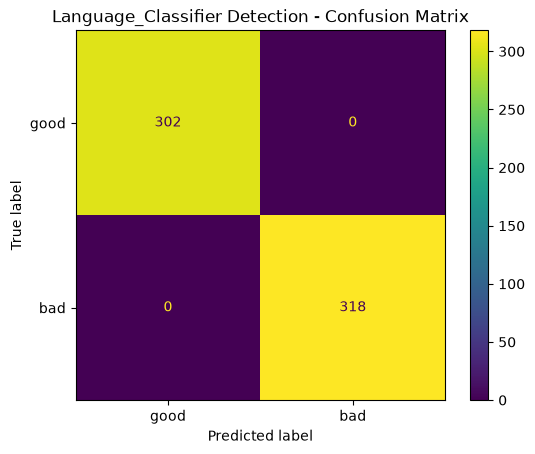

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['good', 'bad'],
    values_format='d'
)

plt.title("Language_Classifier Detection - Confusion Matrix")
plt.show()

In [20]:
import pickle
from sklearn.svm import LinearSVC

# Instantiate the final model with best tuned parameter C=0.01
final_model = LinearSVC(C=0.01, random_state=42, max_iter=5000)

# Train on the entire dataset (X, y)
final_model.fit(X, y)

# Save the model to model.pkl
with open('model.pkl', 'wb') as model_file:
    pickle.dump(final_model, model_file)

# Save the vectorizer to vectorizer.pkl (needed to transform new inputs)
with open('vectorizer.pkl', 'wb') as vec_file:
    pickle.dump(cv, vec_file)

print("Final model successfully saved to 'model.pkl'!")
print("Vectorizer successfully saved to 'vectorizer.pkl'!")

Final model successfully saved to 'model.pkl'!
Vectorizer successfully saved to 'vectorizer.pkl'!
